In [1]:
!pip install -U langchain-tavily

In [2]:
!pip install langgraph langchain langchain_openai langchain_community tavily-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 20.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 46.4 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [langchain_community]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [3]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated #used to construct the agent state
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langchain_openai import ChatOpenAI #langchain wrapper around openAI
from langchain_tavily import TavilySearch
import os
import openai

In [4]:
import os
from getpass import getpass

os.environ["TAVILY_API_KEY"] = getpass(
    "Enter your Tavily API key: "
)

Enter your Tavily API key: ··········


In [5]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=3)

print(type(tool))
print(tool.name)

# Test the search
results = tool.invoke({
    "query": "Latest developments of rain/thunderstorm in Kottayam during last week of October 2026"
})

print(results)

<class 'langchain_tavily.tavily_search.TavilySearch'>
tavily_search
{'query': 'Latest developments of rain/thunderstorm in Kottayam during last week of October 2026', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://en.climate-data.org/asia/india/kerala/kottayam-30069/t/october-10', 'title': 'Weather Kottayam in October 2026: Temperature & Climate', 'content': '| 30. October | 26 °C | 78 °F | 29 °C | 84 °F | 23 °C | 73 °F | 0.2 mm | 0.0 inch. |\n| 31. October | 26 °C | 78 °F | 29 °C | 84 °F | 23 °C | 73 °F | 0.0 mm | 0.0 inch. | [...] | 25. October | 26 °C | 78 °F | 29 °C | 84 °F | 23 °C | 74 °F | 0.3 mm | 0.0 inch. |\n| 26. October | 26 °C | 78 °F | 29 °C | 84 °F | 23 °C | 74 °F | 0.1 mm | 0.0 inch. |\n| 27. October | 26 °C | 78 °F | 29 °C | 84 °F | 23 °C | 73 °F | 0.0 mm | 0.0 inch. |\n| 28. October | 26 °C | 78 °F | 29 °C | 85 °F | 23 °C | 73 °F | 0.1 mm | 0.0 inch. |\n| 29. October | 26 °C | 78 °F | 29 °C | 85 °F | 23 °C | 73 °F | 0.3 mm | 0.0

AgentState

 A shared data structure (here a TypedDict) that carries the agent’s memory, especially the conversation history across graph nodes.
 Ensures complete context for conversation and agent reasoning.

In [6]:
#Define the Agent State
#This structured state keeps track of the conversation history, which is necessary for context when reasoning or taking actions.
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add] #when states are combined, the messages lists are concatenated (added together) rather than replaced.

The Agent class models the AI agent’s behavior, managing how it processes messages (conversations) and interacts with tools.

In [7]:
class Agent:

    def __init__(self, model, tools, system=""):
        self.system = system #save the system message as attribute
        graph = StateGraph(AgentState) #initialize the agent graph (to orchestrate its workflow)
        graph.add_node("llm", self.call_openai) #"llm" node: sends the conversation state to the language model to generate a response or decision.
        graph.add_node("action", self.take_action) #"action" node: executes any actions/tools requested by the model.
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END} #it checks if the LLM requested any tools/actions by calling exists_action.
        )
        graph.add_edge("action", "llm") #After performing an action, it loops back to "llm" for further reasoning or response generation.
        graph.set_entry_point("llm")
        self.graph = graph.compile()
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools) #leting the model to know these tools are available for call (tool invocation)

    def exists_action(self, state: AgentState):
        result = state['messages'][-1] #Checks the latest message in the conversation.
        return len(result.tool_calls) > 0 #if any tool call happens return True, otherwise false

    def call_openai(self, state: AgentState): #collect all list of messages from the state
        messages = state['messages'] #adds system message
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages #If a system prompt is set (instructions/guidelines for the LLM), it's prepended.
        message = self.model.invoke(messages) #model is being invoked here
        return {'messages': [message]} #return the dictionary (it won't override, just added)

    def take_action(self, state: AgentState):
        tool_calls = state['messages'][-1].tool_calls #Takes the latest message's tool calls (requested actions).
        results = []
        for t in tool_calls:
            print(f"Calling: {t}")
            if not t['name'] in self.tools:      # Checks if the tool exists;
                print("\n ....bad tool name....")
                result = "bad tool name, retry"  # if not issues a retry message.
            else:
                result = self.tools[t['name']].invoke(t['args']) #Tool is being invoked here with supplied arguments.
            results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=str(result)))
        print("Back to the model!")
        return {'messages': results} #Returns these results as the next messages to feed back to the LLM for further reasoning.

In [8]:
from getpass import getpass

api_key = getpass("Enter your OpenAI API key: ")

openai.api_key = api_key

Enter your OpenAI API key: ··········


In [11]:
# Set environment variable
os.environ["OPENAI_API_KEY"] = api_key

In [9]:
prompt = """
You are a smart research assistant with access to a web search tool.

Instructions:
1. Search the web when current or factual information is required.
2. Use reliable sources, prioritizing official websites.
3. Read the search results and extract only relevant information.
4. Never display raw tool outputs, JSON, metadata, or internal reasoning.
5. Present the final answer in clear, concise, well-formatted markup language.
6. Use headings and bullet points where appropriate
7. Include source URLs when available.
8. If information is unavailable, state that clearly.
"""

In [12]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model="gpt-5.6",
    use_responses_api=True
)

abot = Agent(model, [tool], system=prompt)

In [13]:
!apt update
!apt install graphviz-dev -y

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.7 kB]
Get:4 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,412 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.0 kB

In [14]:
!pip install pygraphviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 33.1 MB/s  0:00:00


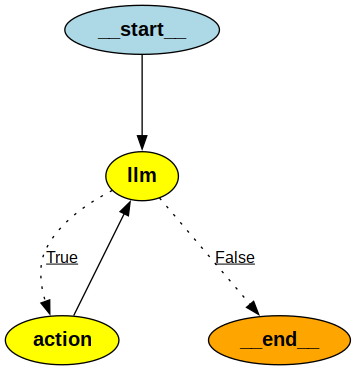

In [15]:
from IPython.display import Image

Image(abot.graph.get_graph().draw_png())

In [17]:
from langchain_core.messages import HumanMessage

messages = [
    HumanMessage(
        content="What is the latest thunderstorm forecast for kottayam during October 2026?"
    )
]

result = abot.graph.invoke({"messages": messages})

print(result["messages"][-1].content)

Calling: {'name': 'tavily_search', 'args': {'query': 'site:mausam.imd.gov.in Kottayam district weather forecast thunderstorm latest', 'include_domains': ['mausam.imd.gov.in'], 'exclude_domains': [], 'search_depth': 'advanced', 'include_images': False, 'time_range': None, 'topic': 'general', 'start_date': None, 'end_date': None}, 'id': 'call_uJbSLM22kolP7bf4pBnG97Gw', 'type': 'tool_call'}
Calling: {'name': 'tavily_search', 'args': {'query': 'site:imd.gov.in long range forecast season India lead time months official', 'include_domains': ['imd.gov.in'], 'exclude_domains': [], 'search_depth': 'advanced', 'include_images': False, 'time_range': None, 'topic': 'general', 'start_date': None, 'end_date': None}, 'id': 'call_9JfW0ZM8w0psBsOkifgNw6Gp', 'type': 'tool_call'}
Calling: {'name': 'tavily_search', 'args': {'query': 'site:mausam.imd.gov.in Kerala October climatology thunderstorm rainfall Kottayam', 'include_domains': ['mausam.imd.gov.in'], 'exclude_domains': [], 'search_depth': 'advanced'

Why the model might perform multiple searches:
1. It wants to find the latest IMD forecast.
2. It wants to verify the information using official sources.
3. It searches for historical October rainfall or climatology.
4. It tries different search queries when the previous results are insufficient.
5. It attempts to identify the latest available forecast document.
Your model is effectively behaving like a research agent rather than a simple question-answering chatbot.

In [19]:
result['messages'][-1].content

[{'id': 'rs_00a975ae18f7a0c6006ae3dae5fce087d2afd4b832a9041f48',
  'summary': [],
  'type': 'reasoning',
  'content': [],
  'encrypted_content': 'gAAAAABq49rsRblL_bXmoRRbeWhArAzE6PSrV4LraJXlGprDrPxs8_BC1KwS9Bx-iYaDWyi-IENk0gJ33OfqcTwGFxvG420fnCaL5xoLdAx3cM2Lp7Tlt9apygX7exeytHOjtQ4P9VTiz7XIwZ6-h7vtPAwK9Q_9mF65tUVDm2iyPwdRxb8z1rAGN-2MoLpACruGWVsOGf5JszzJexGgiUtpEcr4D0o5JSANniqKcOMdMcOobCsvfW-rqL3LjQICbOu31n_-T3jiTR3rbzAhdQlQda1ITSO-mFIaUvGYZXDNyYaeUV20P3cYGhwWRaqfHdq-yjndggSt2oY4gFN02vVSH287gzkGMUD2UoQoYYxxiL-BwOEm5Ru79M2as-keUYDIfY0CeS98LckL8m-YEFTVKZpnmeuCyxbpLOmsG3PlO0aRYtEB7xQAeJcdQsMSl5N2RC3RYm-Sky4EJMDEPdT2vCDxGf7yhtFXMsGQ7Fz2Jt0SXxIdGeH3E_0TCMxBrKBelP-2ty2imvSDRs1f5kvc9ndFXiRhPX_N3NJUUwcX0Odk3NrMULgXpeAgBVum0yiOyctDgqpww6ETXhw0oozCM_cL3VbGwVdPD2ge5icpoTPSGaz8Tw4WqFo2QWBRkULg3mI-h5EMr5uMpn5vcPCqADaiwzyXNBae6yicnC92i-kDb400Q4vkYmZv8bVwQFrOekBPpAf8nOCmL3U1Tu9O2ESWIOIFjtr58oEwbLCt5eHFtF3NJa-CRny2hfm2V3wfAXpKwsJ0VzTnlRRqmWZR8647JhB2ZZfBZSXUZ3VPNNWKZTGtsLJUo2FP_5dVzwvxPlx3VpcYea5ID3-vBq